# Chronos-2 — Brasil a cada 5 minutos

Previsão móvel do **próximo intervalo de 5 minutos**, com **12 observações anteriores (60 minutos)**. Não há agregação diária nem normalização dos horários para meia-noite.

Na primeira etapa, comparamos Chronos-2 sem ajuste de pesos, persistência e as LSTMs local e transferida já treinadas. O teste usa exatamente as mesmas **7.668 datas diurnas de novembro–dezembro de 2025** do experimento anterior. Alvo e última potência da persistência devem ser medidos; apenas o histórico pode conter estimativas causais previamente auditadas. Nenhum parâmetro é escolhido pelo desempenho neste teste.

Dois cenários fixados: potência apenas; potência com calendário. O calendário futuro é conhecido, mas **potência e meteorologia futuras nunca são fornecidas**. Meteorologia horária fica fora desta comparação de resolução de cinco minutos.

API e interpretação das covariáveis: [implementação oficial](https://github.com/amazon-science/chronos-forecasting/blob/main/src/chronos/chronos2/pipeline.py) e [modelo oficial](https://huggingface.co/amazon/chronos-2).

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image


RAIZ = Path.cwd()
if not (RAIZ / 'data/processed/brasil/base_5min_brasil.pkl').exists():
    raise FileNotFoundError('Execute o notebook a partir da raiz do projeto.')
EXPERIMENTO = RAIZ / 'experimentos/transfer_learning_australia_brasil'
PASTA_RESULTADOS = RAIZ / 'resultados_chronos/5min'
PASTA_RESULTADOS.mkdir(parents=True, exist_ok=True)
FREQUENCIA = '5min'
HORIZONTE = 1
JANELA = 12
CAPACIDADE_KW = 1000.0
BATCH_JANELAS = 128
BATCH_MODELO = 64
SEMENTE = 42
CALENDARIO = ['hora_sin', 'hora_cos', 'dia_ano_sin', 'dia_ano_cos']
CENARIOS = {'Chronos2_univariado': [], 'Chronos2_calendario': CALENDARIO}

# Pickle preserva o índice temporal; não usar normalize() nem asfreq('D').
df_brasil = pd.read_pickle(RAIZ / 'data/processed/brasil/base_5min_brasil.pkl')
serie = df_brasil.sort_index().asfreq(FREQUENCIA).copy()
assert serie.index.is_unique
assert (serie.index.to_series().diff().dropna() == pd.Timedelta(minutes=5)).all()
serie['target'] = serie['Active_Power'] / CAPACIDADE_KW
print(f'Base: {len(serie):,} intervalos; {serie.index.min()} a {serie.index.max()}.')
print(f'Alvo original ausente: {serie.Active_Power_original.isna().sum():,} intervalos.')
display(serie[['Active_Power_original', 'Active_Power', 'potencia_estimada', 'diurno']].head())

Base: 105,120 intervalos; 2025-01-01 00:00:00 a 2025-12-31 23:55:00.
Alvo original ausente: 15,097 intervalos.


,Active_Power_original,Active_Power,potencia_estimada,diurno
timestamp,,,,
2025-01-01 00:00:00,0.0,0.0,False,False
2025-01-01 00:05:00,0.0,0.0,False,False
2025-01-01 00:10:00,0.0,0.0,False,False
2025-01-01 00:15:00,0.0,0.0,False,False
2025-01-01 00:20:00,0.0,0.0,False,False


## Janelas e controle das lacunas

Cada janela termina **5 minutos antes** do alvo. A grade real é preservada, sem juntar trechos separados. As datas são as do conjunto de teste já estabelecido; não descartamos casos difíceis para melhorar a comparação. Se uma janela desse conjunto não cumprir os requisitos, o notebook interrompe a execução.

O histórico usa a potência tratada; a avaliação usa exclusivamente `Active_Power_original`, correspondente à soma medida dos oito inversores.

In [2]:
with np.load(EXPERIMENTO / 'dados/brasil_lag12_teste.npz', allow_pickle=False) as arquivo:
    datas_teste = pd.DatetimeIndex(pd.to_datetime(arquivo['datas']))
    reais_referencia = arquivo['y_original'].astype(float) * CAPACIDADE_KW
    persistencia_referencia = arquivo['persistencia'].astype(float) * CAPACIDADE_KW

posicoes = serie.index.get_indexer(datas_teste)
assert len(datas_teste) == 7668 and datas_teste.is_unique
assert (posicoes >= JANELA).all()
indices_contexto = posicoes[:, None] - np.arange(JANELA, 0, -1)[None, :]
assert serie.iloc[posicoes]['diurno'].all()
assert serie.iloc[posicoes]['Active_Power_original'].notna().all()
assert serie.iloc[posicoes - 1]['Active_Power_original'].notna().all()
assert np.isfinite(serie[['target'] + CALENDARIO].to_numpy()[indices_contexto]).all()
np.testing.assert_allclose(serie.iloc[posicoes].Active_Power_original, reais_referencia, atol=1e-3)
np.testing.assert_allclose(serie.iloc[posicoes - 1].Active_Power_original, persistencia_referencia, atol=1e-3)
assert (serie.index[posicoes] - serie.index[posicoes - 1] == pd.Timedelta(minutes=5)).all()

base_avaliacao = pd.DataFrame({
    'timestamp': datas_teste,
    'real_kw': serie.iloc[posicoes].Active_Power_original.to_numpy(),
    'persistencia': serie.iloc[posicoes - 1].Active_Power_original.to_numpy(),
    'historico_estimado_pct': serie.potencia_estimada.to_numpy()[indices_contexto].mean(axis=1) * 100,
})
print(f'{len(datas_teste):,} previsões de +5 minutos; histórico de {JANELA * 5} minutos.')
print(f'Primeiro alvo: {datas_teste.min()}; último: {datas_teste.max()}.')
print('Janelas com algum valor estimado no contexto:', int((base_avaliacao.historico_estimado_pct > 0).sum()))
display(base_avaliacao.head())

7,668 previsões de +5 minutos; histórico de 60 minutos.
Primeiro alvo: 2025-11-01 05:45:00; último: 2025-12-31 18:45:00.
Janelas com algum valor estimado no contexto: 4865


,timestamp,real_kw,persistencia,historico_estimado_pct
0,2025-11-01 05:45:00,5.693,0.000,8.333333
1,2025-11-01 05:50:00,9.335,5.693,8.333333
2,2025-11-01 05:55:00,18.160,9.335,8.333333
3,2025-11-01 06:00:00,27.995,18.160,8.333333
4,2025-11-01 06:05:00,36.527,27.995,8.333333


## Carregar os pesos existentes

Usamos o modelo `amazon/chronos-2` já disponível no cache local, sem treinamento no teste. `cross_learning=False` mantém as janelas de origens diferentes independentes: uma janela posterior não fornece informação a uma anterior. As covariáveis de calendário podem ser conhecidas no instante previsto porque são funções da data e hora.

In [3]:
import torch
from chronos import Chronos2Pipeline
from huggingface_hub.constants import HF_HUB_CACHE

torch.set_num_threads(2)
torch.manual_seed(SEMENTE)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
MODELO_ID = 'amazon/chronos-2'
REVISAO = '29ec3766d36d6f73f0696f85560a422f50e8498c'
# Caminho local evita consultas remotas na detecção de adaptadores do pacote.
MODELO_LOCAL = Path(HF_HUB_CACHE) / 'models--amazon--chronos-2/snapshots' / REVISAO
if not (MODELO_LOCAL / 'model.safetensors').exists():
    raise FileNotFoundError(f'Pesos não encontrados no cache: {MODELO_LOCAL}')
if globals().get('_chronos_revisao') != REVISAO or 'pipeline' not in globals():
    pipeline = Chronos2Pipeline.from_pretrained(
        str(MODELO_LOCAL), device_map=DEVICE, local_files_only=True,
    )
    _chronos_revisao = REVISAO
print('Dispositivo:', DEVICE)
print('Chronos-2 carregado; pacote', importlib.metadata.version('chronos-forecasting'))

c:\Users\Camille\Documents\UFJF\TCC\Leopoldo\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 170/170 [00:00<00:00, 189.88it/s]

Dispositivo: cuda
Chronos-2 carregado; pacote 2.3.2


In [4]:
def prever_lote(inicio, fim, covariaveis):
    # Um identificador por origem. Todas as linhas de contexto precedem o alvo.
    ids = [f'janela_{i:06d}' for i in range(inicio, fim)]
    pos = indices_contexto[inicio:fim]
    colunas = ['target'] + covariaveis
    valores = serie[colunas].to_numpy()[pos].reshape(-1, len(colunas))
    contexto = pd.DataFrame(valores, columns=colunas)
    contexto.insert(0, 'timestamp', serie.index.to_numpy()[pos].reshape(-1))
    contexto.insert(0, 'id', np.repeat(ids, JANELA))
    futuro = None
    if covariaveis:
        futuro = serie.loc[datas_teste[inicio:fim], covariaveis].rename_axis('timestamp').reset_index()
        futuro.insert(0, 'id', ids)
        assert 'target' not in futuro.columns
    with torch.inference_mode():
        saida = pipeline.predict_df(
            contexto, future_df=futuro, prediction_length=HORIZONTE,
            quantile_levels=[0.1, 0.5, 0.9], id_column='id',
            timestamp_column='timestamp', target='target', freq=FREQUENCIA,
            batch_size=BATCH_MODELO, context_length=JANELA,
            cross_learning=False,
        )
    saida = saida.set_index('id').loc[ids]
    assert len(saida) == fim - inicio
    assert (pd.to_datetime(saida.timestamp).to_numpy() == datas_teste[inicio:fim].to_numpy()).all()
    previsoes = saida[['predictions', '0.1', '0.9']].to_numpy(dtype=float) * CAPACIDADE_KW
    assert np.isfinite(previsoes).all()
    # Mesma restrição dos modelos anteriores: potência não negativa, sem teto adicional.
    return np.maximum(previsoes, 0)

# Pequeno controle antes da execução completa: alterar o alvo/futuro não faz parte da entrada.
print('Função preparada: 12 passos passados → 1 passo futuro, sem acessar a potência do alvo.')

Função preparada: 12 passos passados → 1 passo futuro, sem acessar a potência do alvo.


## Executar a comparação

As previsões móveis usam somente o passado disponível em cada origem. Observações do começo do teste podem entrar no histórico de uma previsão posterior, como ocorreria em operação; os pesos permanecem fixos.

Os resultados parciais são salvos a cada lote para permitir retomar a execução sem refazer inferências. A assinatura impede reutilizar previsões de outra base, configuração ou versão do pacote.

In [5]:
arquivo_base = RAIZ / 'data/processed/brasil/base_5min_brasil.pkl'
config_execucao = {
    'modelo': MODELO_ID, 'revisao': REVISAO,
    'chronos_version': importlib.metadata.version('chronos-forecasting'),
    'torch_version': torch.__version__, 'dispositivo': DEVICE,
    'frequencia': FREQUENCIA, 'contexto_passos': JANELA, 'horizonte_passos': HORIZONTE,
    'capacidade_kw': CAPACIDADE_KW, 'batch_janelas': BATCH_JANELAS,
    'batch_modelo': BATCH_MODELO, 'cross_learning': False, 'semente': SEMENTE,
    'cenarios': CENARIOS, 'pos_processamento': 'clip inferior em zero, sem teto',
    'base_sha256': hashlib.file_digest(arquivo_base.open('rb'), 'sha256').hexdigest(),
    'datas_sha256': hashlib.sha256(datas_teste.to_numpy().tobytes()).hexdigest(),
    'n': len(datas_teste), 'inicio_teste': str(datas_teste.min()), 'fim_teste': str(datas_teste.max()),
}
assinatura = hashlib.sha256(json.dumps(config_execucao, sort_keys=True).encode()).hexdigest()
parciais = PASTA_RESULTADOS / 'parciais' / assinatura[:16]
parciais.mkdir(parents=True, exist_ok=True)
(parciais / 'config.json').write_text(json.dumps(config_execucao, indent=2), encoding='utf-8')
df_previsoes_chronos = base_avaliacao.copy()
for nome, covariaveis in CENARIOS.items():
    partes = []
    for inicio in range(0, len(datas_teste), BATCH_JANELAS):
        fim = min(inicio + BATCH_JANELAS, len(datas_teste))
        caminho = parciais / f'{nome}_{inicio:06d}.npy'
        if caminho.exists():
            previsto = np.load(caminho, allow_pickle=False)
        else:
            previsto = prever_lote(inicio, fim, covariaveis)
            np.save(caminho, previsto)
        assert previsto.shape == (fim - inicio, 3) and np.isfinite(previsto).all()
        partes.append(previsto)
        (PASTA_RESULTADOS / 'progresso.json').write_text(
            json.dumps({'cenario': nome, 'concluidas': fim, 'total': len(datas_teste)}), encoding='utf-8')
    valores = np.concatenate(partes)
    df_previsoes_chronos[nome] = valores[:, 0]
    df_previsoes_chronos[f'{nome}_q10'] = valores[:, 1]
    df_previsoes_chronos[f'{nome}_q90'] = valores[:, 2]
    print(f'{nome}: {len(valores):,} previsões concluídas.')

# Trazer as cinco sementes das duas estratégias LSTM, sempre nas mesmas datas.
fonte = EXPERIMENTO / 'resultados/teste_previsoes.csv'
partes = []
for pedaco in pd.read_csv(fonte, chunksize=100_000):
    selecionado = pedaco[(pedaco.arquitetura == 'lstm_direta') & (pedaco.lag == JANELA)
                        & pedaco.metodo.isin(['local', 'completo'])].copy()
    if len(selecionado):
        partes.append(selecionado)
referencias = pd.concat(partes, ignore_index=True)
referencias['timestamp'] = pd.to_datetime(referencias.timestamp)
for (metodo, seed), grupo in referencias.groupby(['metodo', 'seed']):
    grupo = grupo.set_index('timestamp').reindex(datas_teste)
    assert grupo.previsto_kw.notna().all()
    np.testing.assert_allclose(grupo.real_kw, df_previsoes_chronos.real_kw, atol=1e-3)
    np.testing.assert_allclose(grupo.persistencia_kw, df_previsoes_chronos.persistencia, atol=1e-3)
    df_previsoes_chronos[f'LSTM_{metodo}_seed{seed}'] = grupo.previsto_kw.to_numpy()

df_previsoes_chronos.to_csv(PASTA_RESULTADOS / 'previsoes_chronos_5min.csv', index=False)
(PASTA_RESULTADOS / 'config_execucao.json').write_text(json.dumps(config_execucao, indent=2), encoding='utf-8')
print('Previsões salvas em', PASTA_RESULTADOS)

Chronos2_univariado: 7,668 previsões concluídas.
Chronos2_calendario: 7,668 previsões concluídas.
Previsões salvas em c:\Users\Camille\Documents\UFJF\TCC\Leopoldo\resultados_chronos\5min


## Métricas no mesmo conjunto de teste

MAE e RMSE em kW; skill positivo indica redução do erro em relação à persistência. As LSTMs são resumidas pela **média das métricas das cinco sementes**, sem criar um ensemble. O desvio entre sementes não é um intervalo de confiança temporal. O resultado compara estratégias já definidas e não seleciona uma nova arquitetura pelo teste.

In [6]:
real = df_previsoes_chronos.real_kw.to_numpy()
persistencia = df_previsoes_chronos.persistencia.to_numpy()
mae_ref = np.abs(real - persistencia).mean()
rmse_ref = np.sqrt(np.mean((real - persistencia) ** 2))

def calcular_metricas(nome, previsto):
    erro = np.asarray(previsto) - real
    mae = np.abs(erro).mean()
    rmse = np.sqrt(np.mean(erro ** 2))
    return {'modelo': nome, 'n': len(real), 'MAE_kW': mae, 'RMSE_kW': rmse,
            'nRMSE_capacidade_pct': 100 * rmse / CAPACIDADE_KW,
            'WAPE_pct': 100 * np.abs(erro).sum() / np.abs(real).sum(),
            'Skill_MAE_pct': 100 * (1 - mae / mae_ref),
            'Skill_RMSE_pct': 100 * (1 - rmse / rmse_ref), 'BIAS_kW': erro.mean()}

linhas = [calcular_metricas(nome, df_previsoes_chronos[nome])
          for nome in ['persistencia'] + list(CENARIOS)]
metricas_por_seed = []
for metodo in ['local', 'completo']:
    grupo = []
    for seed in [42, 7, 21, 84, 123]:
        m = calcular_metricas(f'LSTM_{metodo}', df_previsoes_chronos[f'LSTM_{metodo}_seed{seed}'])
        metricas_por_seed.append(dict(m, seed=seed))
        grupo.append(m)
    g = pd.DataFrame(grupo)
    resumo = {'modelo': f'LSTM_{metodo}', **g.select_dtypes('number').mean().to_dict()}
    resumo['RMSE_dp_sementes_kW'] = g.RMSE_kW.std(ddof=1)
    linhas.append(resumo)
df_metricas_chronos = pd.DataFrame(linhas)
df_metricas_chronos['n'] = df_metricas_chronos['n'].astype(int)
df_metricas_chronos.to_csv(PASTA_RESULTADOS / 'metricas_chronos_5min.csv', index=False)
pd.DataFrame(metricas_por_seed).to_csv(PASTA_RESULTADOS / 'metricas_lstm_por_seed.csv', index=False)
display(df_metricas_chronos.round(3))

for nome in CENARIOS:
    r = df_metricas_chronos.set_index('modelo').loc[nome]
    print(f'{nome}: skill RMSE vs. persistência = {r.Skill_RMSE_pct:+.2f}%; MAE = {r.MAE_kW:.2f} kW.')

,modelo,n,MAE_kW,RMSE_kW,nRMSE_capacidade_pct,WAPE_pct,Skill_MAE_pct,Skill_RMSE_pct,BIAS_kW,RMSE_dp_sementes_kW
0,persistencia,7668,91.201,182.621,18.262,21.294,0.000,0.000,0.382,NaN
1,Chronos2_univariado,7668,90.138,171.547,17.155,21.046,1.165,6.064,-0.312,NaN
2,Chronos2_calendario,7668,93.021,175.652,17.565,21.719,-1.995,3.816,-0.008,NaN
3,LSTM_local,7668,93.182,156.969,15.697,21.757,-2.172,14.047,2.457,0.206
4,LSTM_completo,7668,93.055,157.029,15.703,21.727,-2.034,14.014,2.869,0.151


Chronos2_univariado: skill RMSE vs. persistência = +6.06%; MAE = 90.14 kW.
Chronos2_calendario: skill RMSE vs. persistência = +3.82%; MAE = 93.02 kW.


## Gráficos

A primeira figura mostra os **primeiros cinco dias corridos do teste** e a segunda resume todo o teste. A escolha do trecho é fixa, independente do erro. A grade de cinco minutos e os NaNs interrompem as linhas nos períodos sem avaliação, evitando ligar dias diferentes. As curvas LSTM usam a semente 42; a tabela acima resume as cinco sementes.

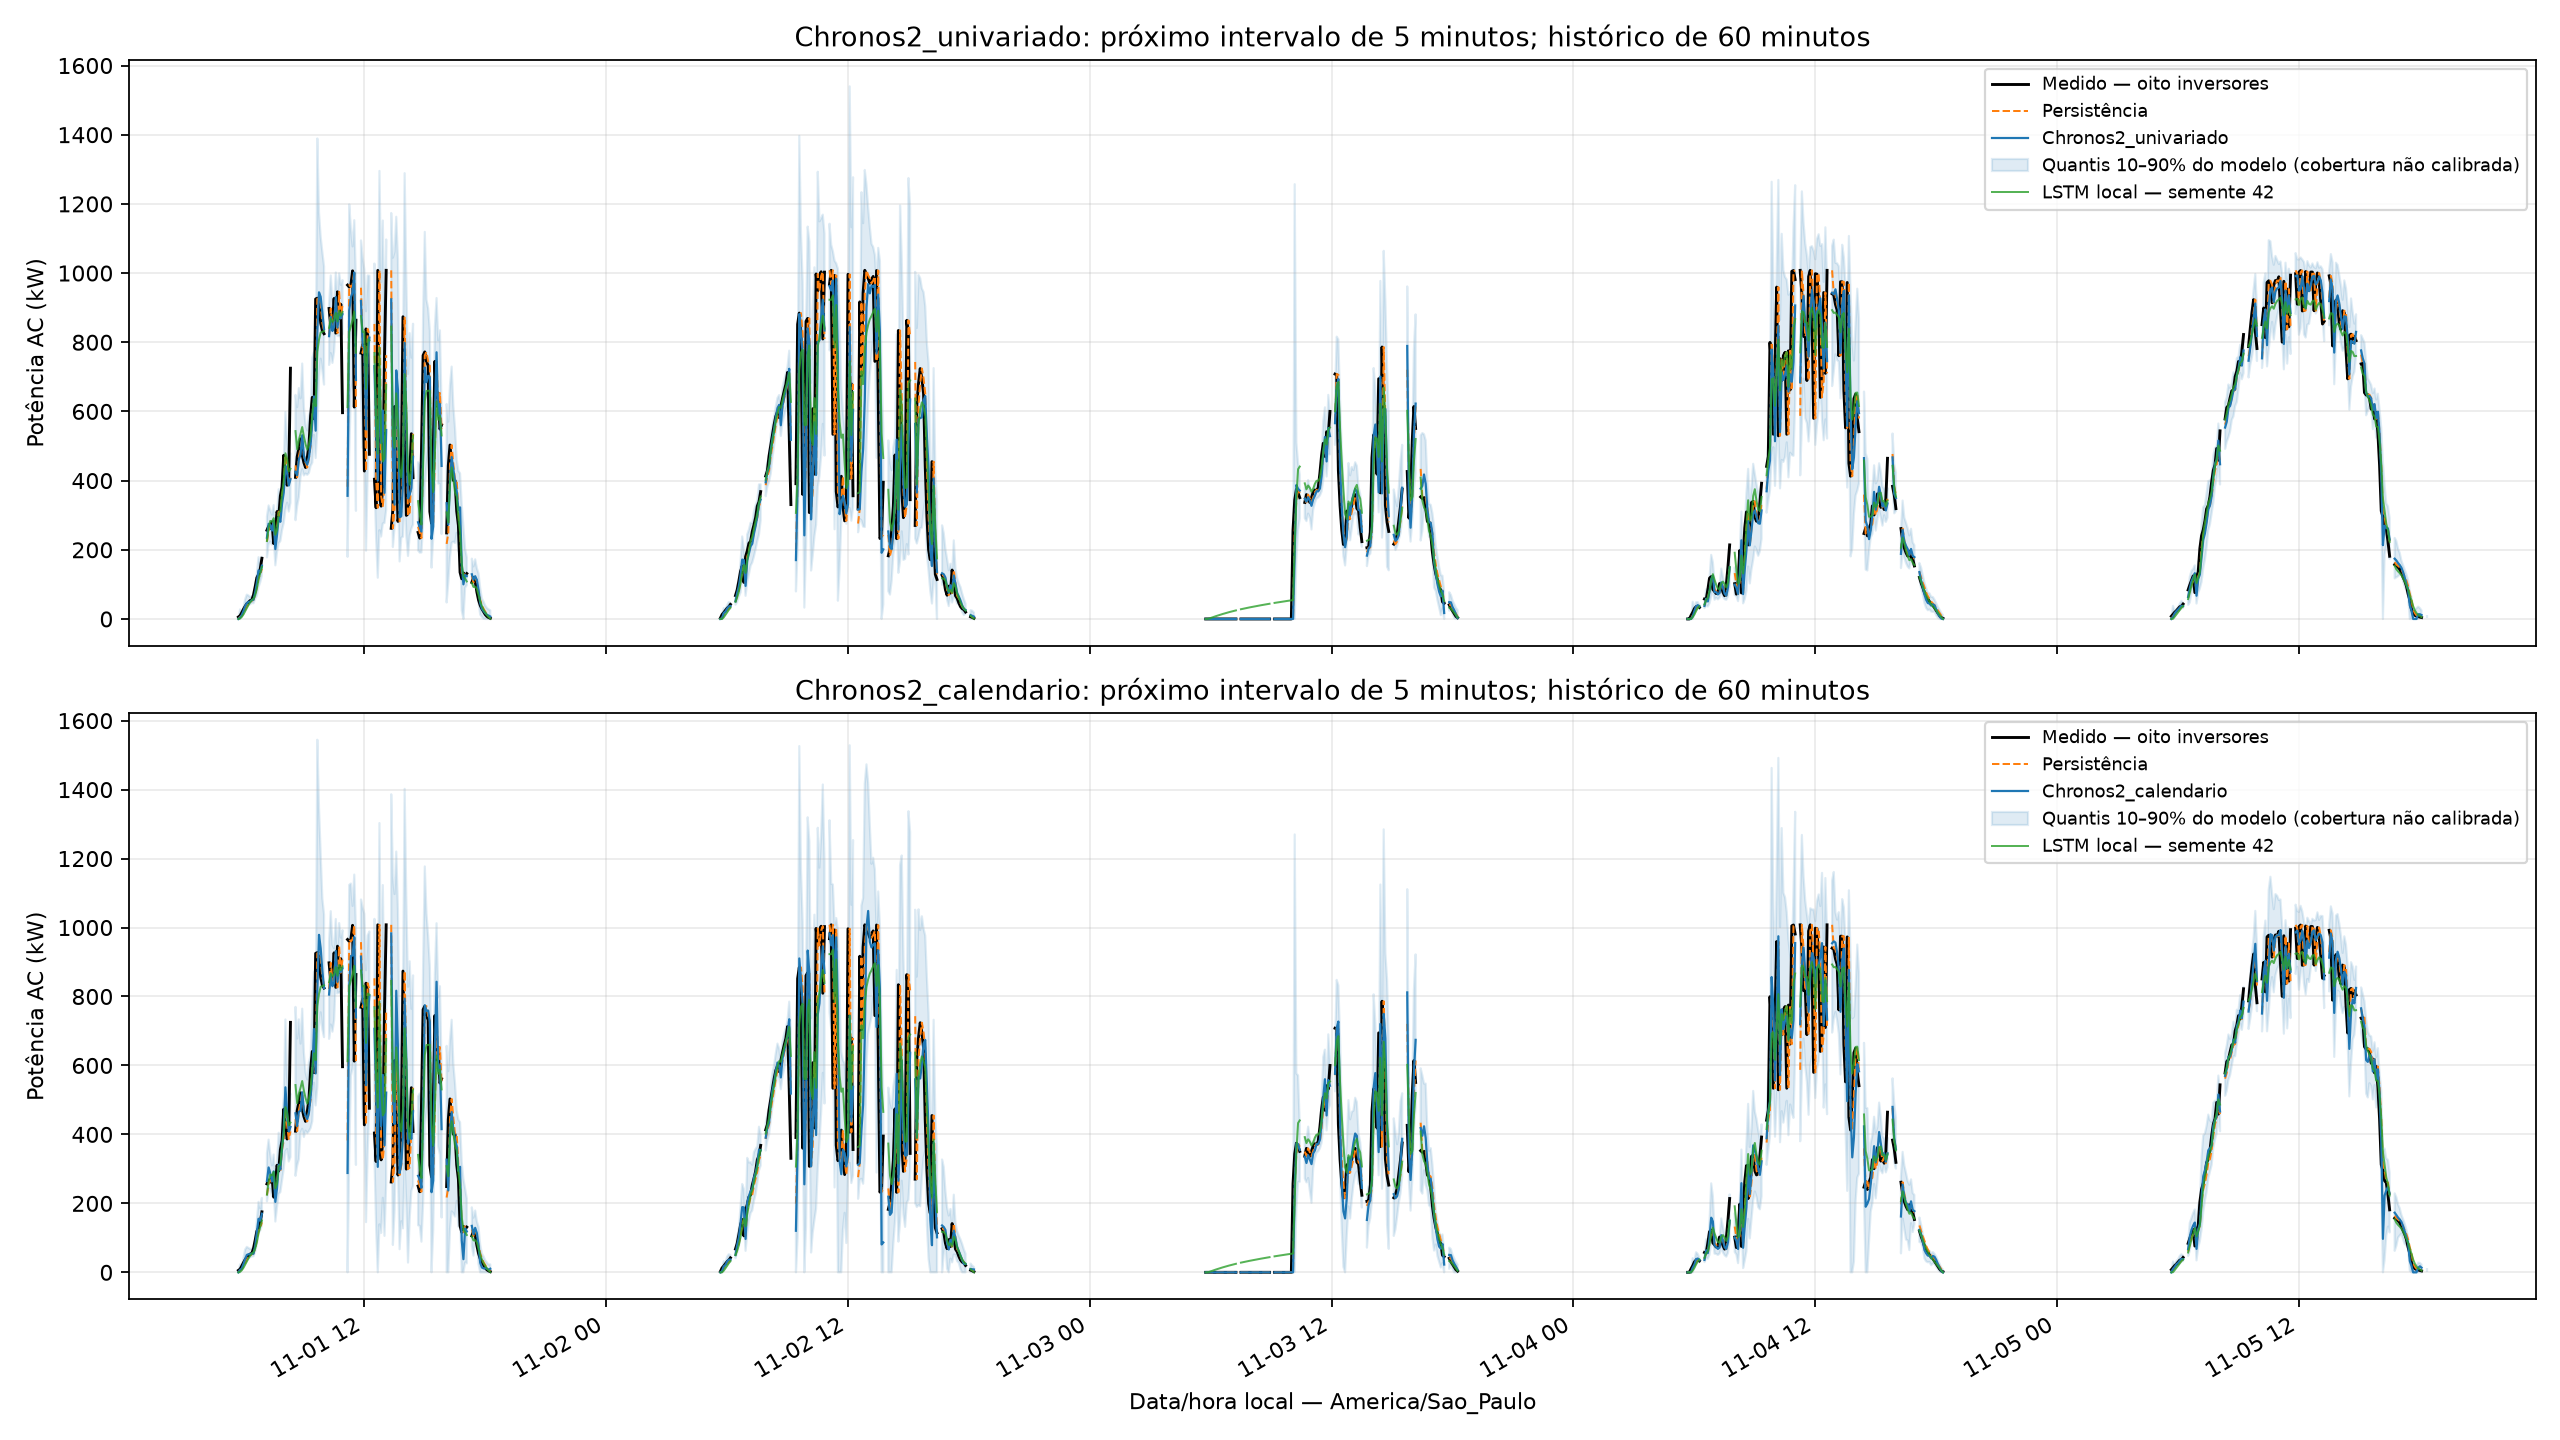

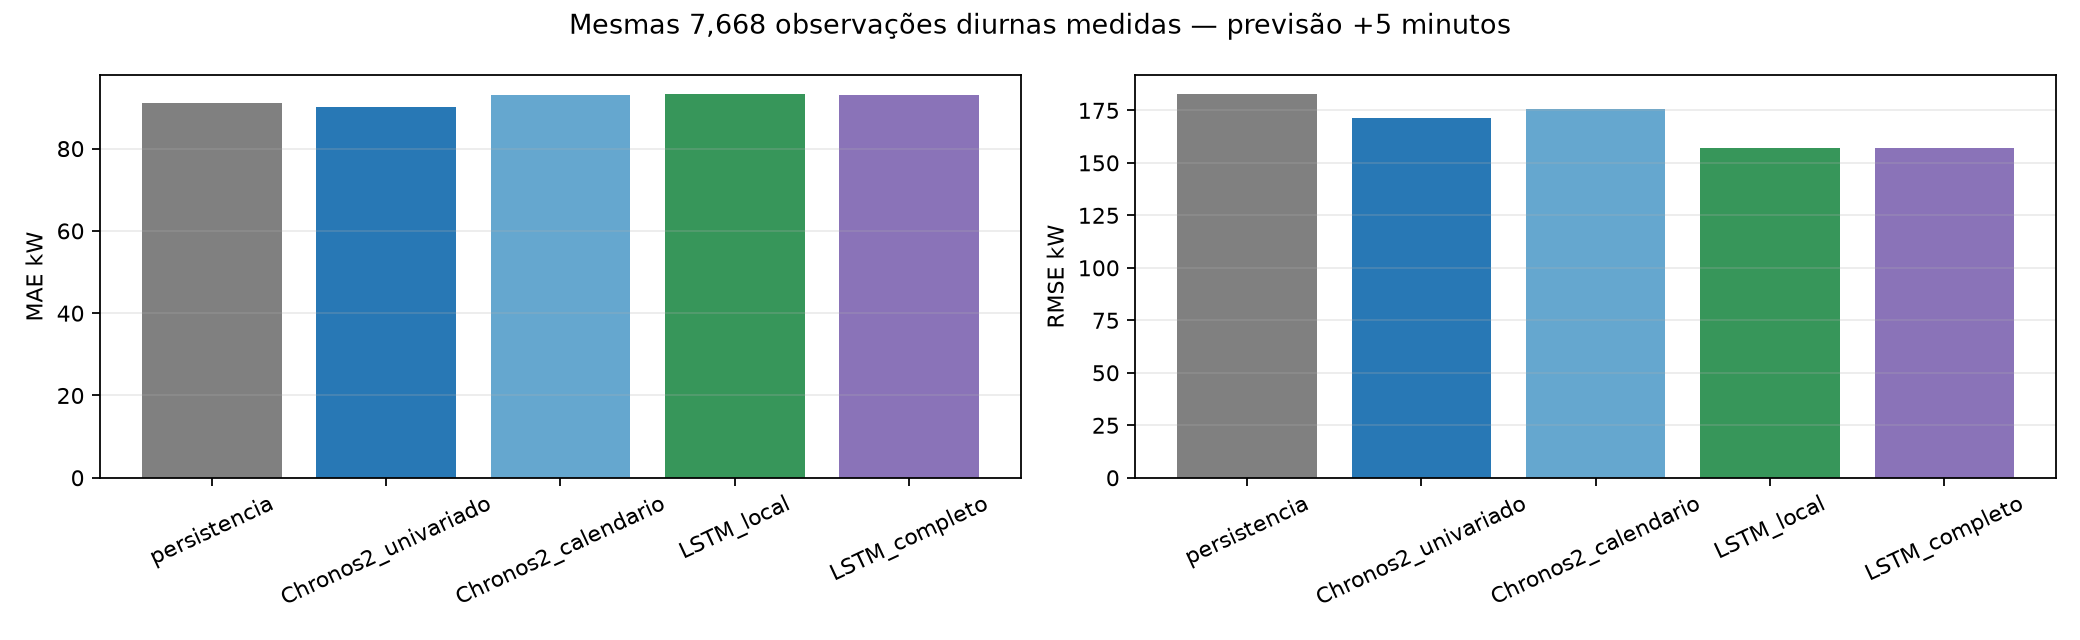

Gráficos e tabelas: c:\Users\Camille\Documents\UFJF\TCC\Leopoldo\resultados_chronos\5min


In [7]:
inicio = datas_teste.min().normalize()
fim = inicio + pd.Timedelta(days=5)
grade = pd.date_range(inicio, fim, freq=FREQUENCIA, inclusive='left')
trecho = df_previsoes_chronos.set_index('timestamp').reindex(grade)
fig, eixos = plt.subplots(2, 1, figsize=(16, 9), sharex=True)
for ax, nome in zip(eixos, CENARIOS):
    ax.plot(grade, trecho.real_kw, color='black', lw=1.3, label='Medido — oito inversores')
    ax.plot(grade, trecho.persistencia, color='tab:orange', lw=0.9, ls='--', label='Persistência')
    ax.plot(grade, trecho[nome], color='tab:blue', lw=1, label=nome)
    ax.fill_between(grade, trecho[f'{nome}_q10'], trecho[f'{nome}_q90'], color='tab:blue', alpha=0.14,
                    label='Quantis 10–90% do modelo (cobertura não calibrada)')
    ax.plot(grade, trecho.LSTM_local_seed42, color='tab:green', lw=0.9, alpha=0.8, label='LSTM local — semente 42')
    ax.set_ylabel('Potência AC (kW)')
    ax.set_title(f'{nome}: próximo intervalo de 5 minutos; histórico de 60 minutos')
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8, loc='upper right')
eixos[-1].set_xlabel('Data/hora local — America/Sao_Paulo')
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(PASTA_RESULTADOS / 'previsoes_chronos_5min.png', dpi=160)
display(Image(filename=str(PASTA_RESULTADOS / 'previsoes_chronos_5min.png')))
plt.close(fig)

fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
for ax, metrica in zip(eixos, ['MAE_kW', 'RMSE_kW']):
    ax.bar(df_metricas_chronos.modelo, df_metricas_chronos[metrica], color=['gray', '#2878b5', '#65a7cf', '#37965a', '#8a73b8'])
    ax.set_ylabel(metrica.replace('_', ' '))
    ax.tick_params(axis='x', rotation=25)
    ax.grid(axis='y', alpha=0.25)
fig.suptitle(f'Mesmas {len(real):,} observações diurnas medidas — previsão +5 minutos')
fig.tight_layout()
fig.savefig(PASTA_RESULTADOS / 'comparacao_metricas_5min.png', dpi=160)
display(Image(filename=str(PASTA_RESULTADOS / 'comparacao_metricas_5min.png')))
plt.close(fig)
print('Gráficos e tabelas:', PASTA_RESULTADOS)

## Alcance da etapa sem ajuste

Este é um teste de Chronos-2 **sem ajuste de pesos**, com contexto fixo de 60 minutos. Um eventual resultado inferior não exclui contextos mais longos ou fine-tuning, que precisariam ser escolhidos na validação, preservando um teste futuro. As métricas diárias anteriores medem outra tarefa e não são comparáveis diretamente a estas métricas de cinco minutos.

O calendário futuro é conhecido; o teste não usa meteorologia observada no futuro. As séries horárias de meteorologia pública não se tornam observações nativas de cinco minutos. A avaliação diurna evita que zeros noturnos dominem a comparação.

## Fine-tuning com LoRA: cinco cenários do artigo

Referência solicitada: [Five Ways to Fine-Tune Chronos-2](https://towardsdatascience.com/five-ways-to-fine-tune-chronos-2-the-time-series-foundation-model/), de Shuai Guo, e [notebook público do autor](https://github.com/ShuaiGuo16/chronos-2-forecasting/blob/main/02_chronos2_fine_tuning_building_demand.ipynb). Conferimos a API na [implementação oficial do Chronos](https://github.com/amazon-science/chronos-forecasting/blob/main/src/chronos/chronos2/pipeline.py).

O artigo usa oito edifícios **sintéticos**, dados horários e horizonte de uma semana. Aqui adaptamos o desenho às **duas usinas reais**, contexto de 60 minutos e horizonte de 5 minutos; os resultados do artigo não são uma estimativa de ganho para energia solar.

| Cenário do artigo | Adaptação neste projeto |
|---|---|
| Um ativo | LoRA na potência do Brasil |
| Portfólio | LoRA compartilhado entre Austrália e Brasil |
| Um ativo + covariáveis | LoRA Brasil com calendário conhecido |
| Portfólio + covariáveis | LoRA Austrália + Brasil com calendário |
| Ativo excluído do ajuste | LoRA apenas na Austrália, aplicado no Brasil |

Mantemos `r=8`, `alpha=16`, projeções Q/K/V/O e saída, taxa de aprendizado `2e-5`, até **1.000 passos** e paciência de seis verificações. Avaliamos checkpoints a cada **50 passos**, em 512 origens distribuídas no tempo. O lote contém **16 origens**, contando separadamente as cinco variáveis no cenário com calendário, conforme a semântica da API. Há uma semente fixa (42): esta etapa é um experimento exploratório, sem alegação de significância estatística.

**Treino:** Brasil até setembro de 2025; Austrália até 2022. **Checkpoints:** outubro de 2025 para Brasil e 2023 para Austrália; no portfólio, 256 origens por usina. A perda de quantis da API escolhe o checkpoint. Depois, o RMSE em **todas as 4.043 origens de outubro** escolhe a estratégia brasileira. O cenário que exclui o Brasil escolhe seu checkpoint somente na Austrália e fica fora dessa seleção brasileira.

Não concatenamos blocos separados como se fossem consecutivos. Cada tarefa de treinamento contém 12 valores passados tratados e **um alvo originalmente medido**. `min_past=12` força a amostragem a prever esse último valor, impedindo treinar com um alvo imputado. O portfólio equilibra o número de origens das duas usinas; potência é normalizada pela capacidade AC de cada uma.

**Limite do estudo:** novembro–dezembro de 2025 já foram consultados nas etapas anteriores. Continuamos escolhendo os ajustes pela validação, mas esta nova comparação no teste é **exploratória** e requer confirmação em um período ainda não consultado. Na transferência sem Brasil, o contexto brasileiro recente é fornecido na inferência; os pesos e o checkpoint não usam rótulos brasileiros.

In [8]:
import sys
import gc
sys.path.insert(0, str(RAIZ / 'src'))
from energia_transfer.chronos_experimentos import preparar, treinar, avaliar

dados_chronos = preparar(RAIZ)
display(pd.DataFrame(dados_chronos['cfg']['cenarios']))
print('Configuração:', RAIZ / 'experimentos/chronos_5min/config.json')
print('Assinatura das bases, configurações e versões:', dados_chronos['assinatura'])

  dominio  particao     n              inicio                 fim  capacidade_ac_kw
   brasil    treino 31874 2025-01-01 06:55:00 2025-09-30 18:10:00            1000.0
   brasil validacao  4043 2025-10-01 06:00:00 2025-10-31 18:15:00            1000.0
   brasil     teste  7668 2025-11-01 05:45:00 2025-12-31 18:45:00            1000.0
australia    treino 40704 2013-07-25 17:35:00 2022-12-31 18:25:00              24.0
australia validacao   512 2023-01-01 05:55:00 2023-12-31 19:20:00              24.0


,nome,dominios,calendario
0,individual,[brasil],False
1,portfolio,"[australia, brasil]",False
2,individual_calendario,[brasil],True
3,portfolio_calendario,"[australia, brasil]",True
4,transferencia_sem_brasil,[australia],True


Configuração: c:\Users\Camille\Documents\UFJF\TCC\Leopoldo\experimentos\chronos_5min\config.json
Assinatura das bases, configurações e versões: b6fa21ba84ad0a7855afa6f2335b8570260cfac314c092bf3da77dd2d29170b5


### Ajustar os cinco adaptadores

Os pesos originais ficam congelados. A auditoria registra o número de parâmetros treináveis e verifica o hash dos parâmetros congelados antes e depois de cada treino. Modelos já concluídos são reutilizados somente se a assinatura e os pesos coincidirem. Os históricos, adaptadores e registros ficam em `experimentos/chronos_5min/modelos/`.

Para repetir a etapa fora do notebook: `.venv/Scripts/python.exe experimentos/chronos_5min/executar.py todas`.

In [9]:
# Liberar o pipeline da etapa zero-shot antes dos ajustes para economizar VRAM.
if 'pipeline' in globals():
    del pipeline
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
treinar(dados_chronos)
auditorias = [json.loads(p.read_text(encoding='utf-8'))
              for p in (dados_chronos['pasta'] / 'modelos').glob('*/concluido.json')]
df_auditoria_lora = pd.DataFrame(auditorias)
assert len(df_auditoria_lora) == 5
assert df_auditoria_lora.congelados_sha256_antes.eq(df_auditoria_lora.congelados_sha256_depois).all()
display(df_auditoria_lora[['cenario', 'parametros_treinaveis', 'parametros_totais',
                           'passos_executados', 'melhor_loss', 'segundos', 'memoria_cuda_max_mib']])

Loading weights: 100%|██████████| 170/170 [00:00<00:00, 237.44it/s]

Reutilizando adaptador verificado: individual
Reutilizando adaptador verificado: portfolio
Reutilizando adaptador verificado: individual_calendario


Reutilizando adaptador verificado: portfolio_calendario
Reutilizando adaptador verificado: transferencia_sem_brasil


,cenario,parametros_treinaveis,parametros_totais,passos_executados,melhor_loss,segundos,memoria_cuda_max_mib
0,individual,1206912,120684576,1000,0.354383,777.372404,1222.55957
1,individual_calendario,1206912,120684576,1000,0.070577,771.413139,1352.88916
2,portfolio,1206912,120684576,900,0.303752,661.420002,1222.55957
3,portfolio_calendario,1206912,120684576,1000,0.059731,772.922279,1352.88916
4,transferencia_sem_brasil,1206912,120684576,1000,0.050345,757.566519,1352.88916


### Validação, comparação final e gráficos

Primeiro são calculadas as métricas de outubro e gravada a decisão. Depois são avaliadas as mesmas 7.668 origens medidas de novembro–dezembro. A comparação inclui os cinco adaptadores, as duas versões zero-shot, persistência e LSTMs. Compare cada adaptador com o zero-shot correspondente: potência com potência, calendário com calendário. WAPE acompanha o artigo; MAE e RMSE preservam as métricas do projeto.

As LSTMs continuam resumidas pela média das métricas de cinco sementes. Os adaptadores usam uma semente, portanto essa diferença no número de repetições deve acompanhar qualquer interpretação dos resultados.

A previsão pontual do Chronos é a mediana (quantil 0,5), como em `predict_df`; o ajuste usa perda de quantis. As LSTMs anteriores usam MSE, portanto os objetivos de treinamento diferem e os ganhos em MAE e RMSE podem divergir.


validacao: zero_shot_univariado; RMSE 138.281 kW
validacao: zero_shot_calendario; RMSE 141.725 kW


Loading weights: 100%|██████████| 170/170 [00:00<00:00, 212.02it/s]


validacao: individual; RMSE 137.126 kW


Loading weights: 100%|██████████| 170/170 [00:00<00:00, 201.43it/s]


validacao: portfolio; RMSE 139.521 kW


...

Loading weights: 100%|██████████| 170/170 [00:00<00:00, 205.02it/s]


teste: transferencia_sem_brasil; RMSE 172.921 kW
Escolhido pelo RMSE de outubro: individual_calendario
Transferência sem Brasil: checkpoint escolhido só na Austrália; fora da seleção brasileira.


,modelo,n,MAE_kW,RMSE_kW,WAPE_pct,Skill_RMSE_pct,BIAS_kW
0,persistencia,4043,63.940,143.259,13.293,0.000,-0.172
1,zero_shot_univariado,4043,62.988,138.281,13.095,3.475,1.367
2,zero_shot_calendario,4043,65.369,141.725,13.590,1.071,-0.014
3,individual,4043,61.779,137.126,12.844,4.281,7.818
4,portfolio,4043,62.296,139.521,12.951,2.609,9.640
5,individual_calendario,4043,60.380,134.807,12.553,5.900,7.317
6,portfolio_calendario,4043,60.386,135.759,12.554,5.236,7.349
7,transferencia_sem_brasil,4043,60.892,137.031,12.660,4.347,4.928


,modelo,n,MAE_kW,RMSE_kW,WAPE_pct,Skill_RMSE_pct,BIAS_kW,escolhido_validacao_chronos
0,persistencia,7668,91.201,182.621,21.294,0.000,0.382,False
1,zero_shot_univariado,7668,90.138,171.547,21.046,6.064,-0.312,False
2,zero_shot_calendario,7668,93.021,175.652,21.719,3.816,-0.008,False
3,individual,7668,89.193,171.961,20.825,5.837,6.905,False
4,portfolio,7668,89.777,174.585,20.961,4.400,10.448,False
5,individual_calendario,7668,88.014,170.156,20.550,6.826,7.743,True
6,portfolio_calendario,7668,88.116,171.200,20.574,6.254,8.043,False
7,transferencia_sem_brasil,7668,88.814,172.921,20.737,5.312,5.355,False
8,LSTM_local,7668,93.182,156.969,21.757,14.047,2.457,False
9,LSTM_completo,7668,93.055,157.029,21.727,14.014,2.869,False


,cenario,referencia,ganho_RMSE_pct,ganho_WAPE_pct
0,individual,zero_shot_univariado,-0.242,1.048
1,portfolio,zero_shot_univariado,-1.771,0.401
2,individual_calendario,zero_shot_calendario,3.129,5.382
3,portfolio_calendario,zero_shot_calendario,2.535,5.273
4,transferencia_sem_brasil,zero_shot_calendario,1.555,4.522


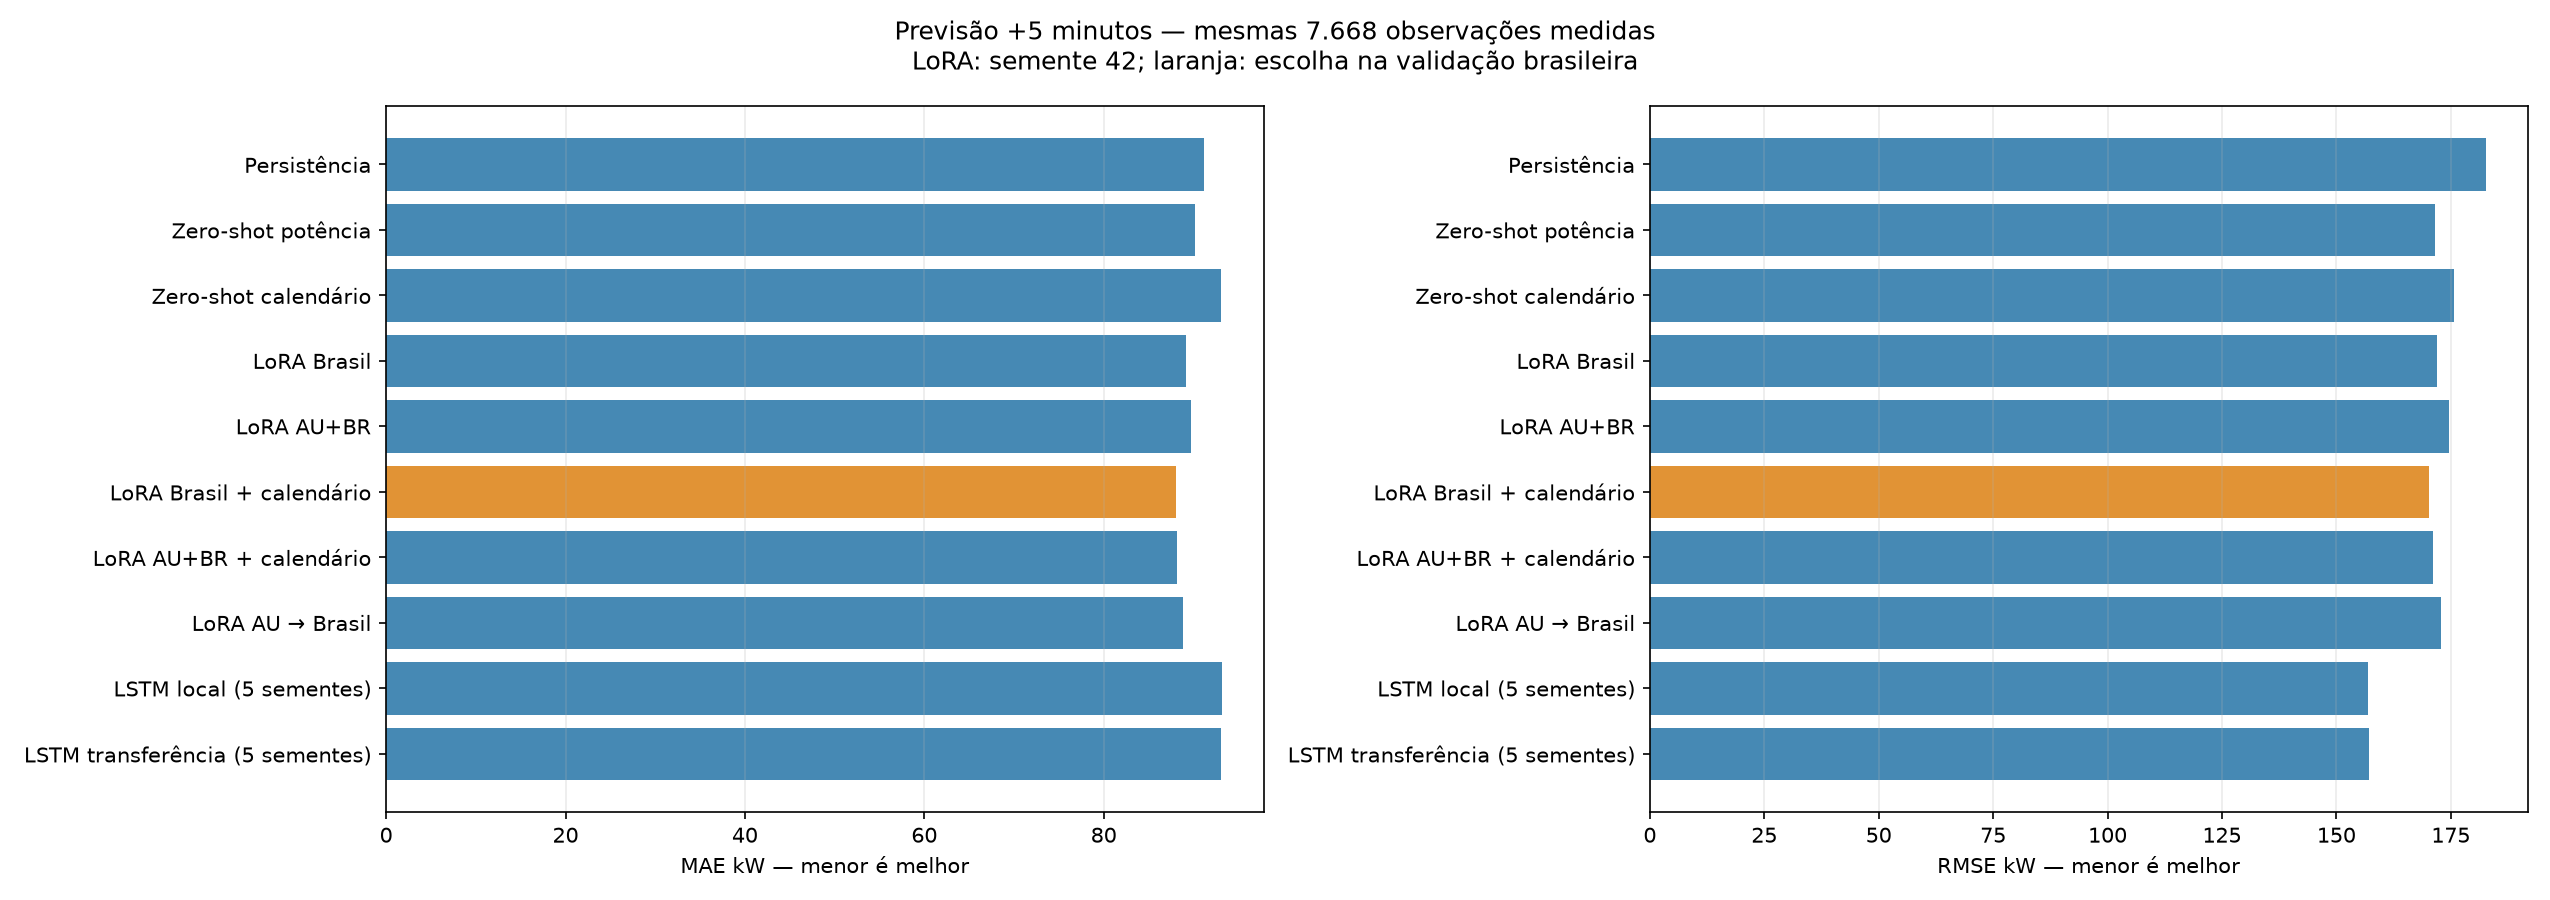

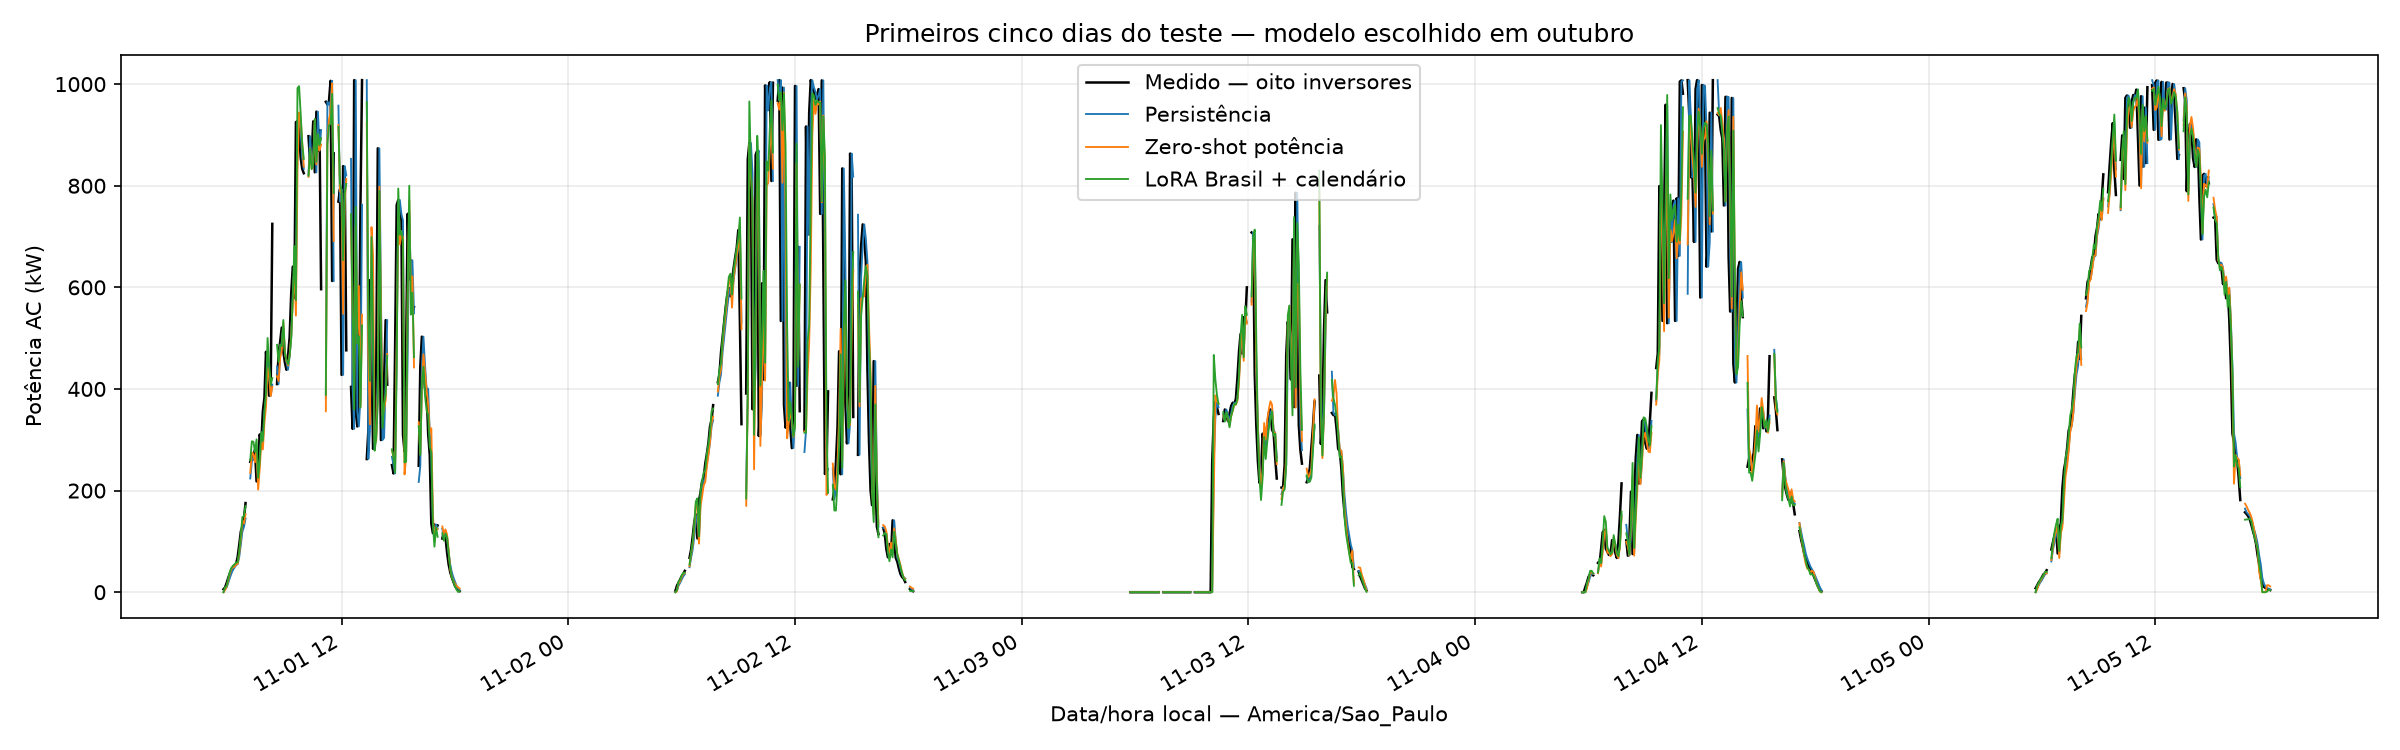

In [10]:
df_comparacao_lora = avaliar(dados_chronos)
decisao_lora = json.loads((dados_chronos['out'] / 'decisao_validacao.json').read_text(encoding='utf-8'))
print('Escolhido pelo RMSE de outubro:', decisao_lora['escolhido']['modelo'])
print('Transferência sem Brasil: checkpoint escolhido só na Austrália; fora da seleção brasileira.')
display(pd.read_csv(dados_chronos['out'] / 'metricas_validacao.csv').round(3))
display(df_comparacao_lora.round(3))
display(pd.read_csv(dados_chronos['out'] / 'ganhos_pareados.csv').round(3))
for nome in ['comparacao_cinco_cenarios.png', 'previsoes_escolha_validacao.png']:
    display(Image(filename=str(dados_chronos['out'] / nome)))

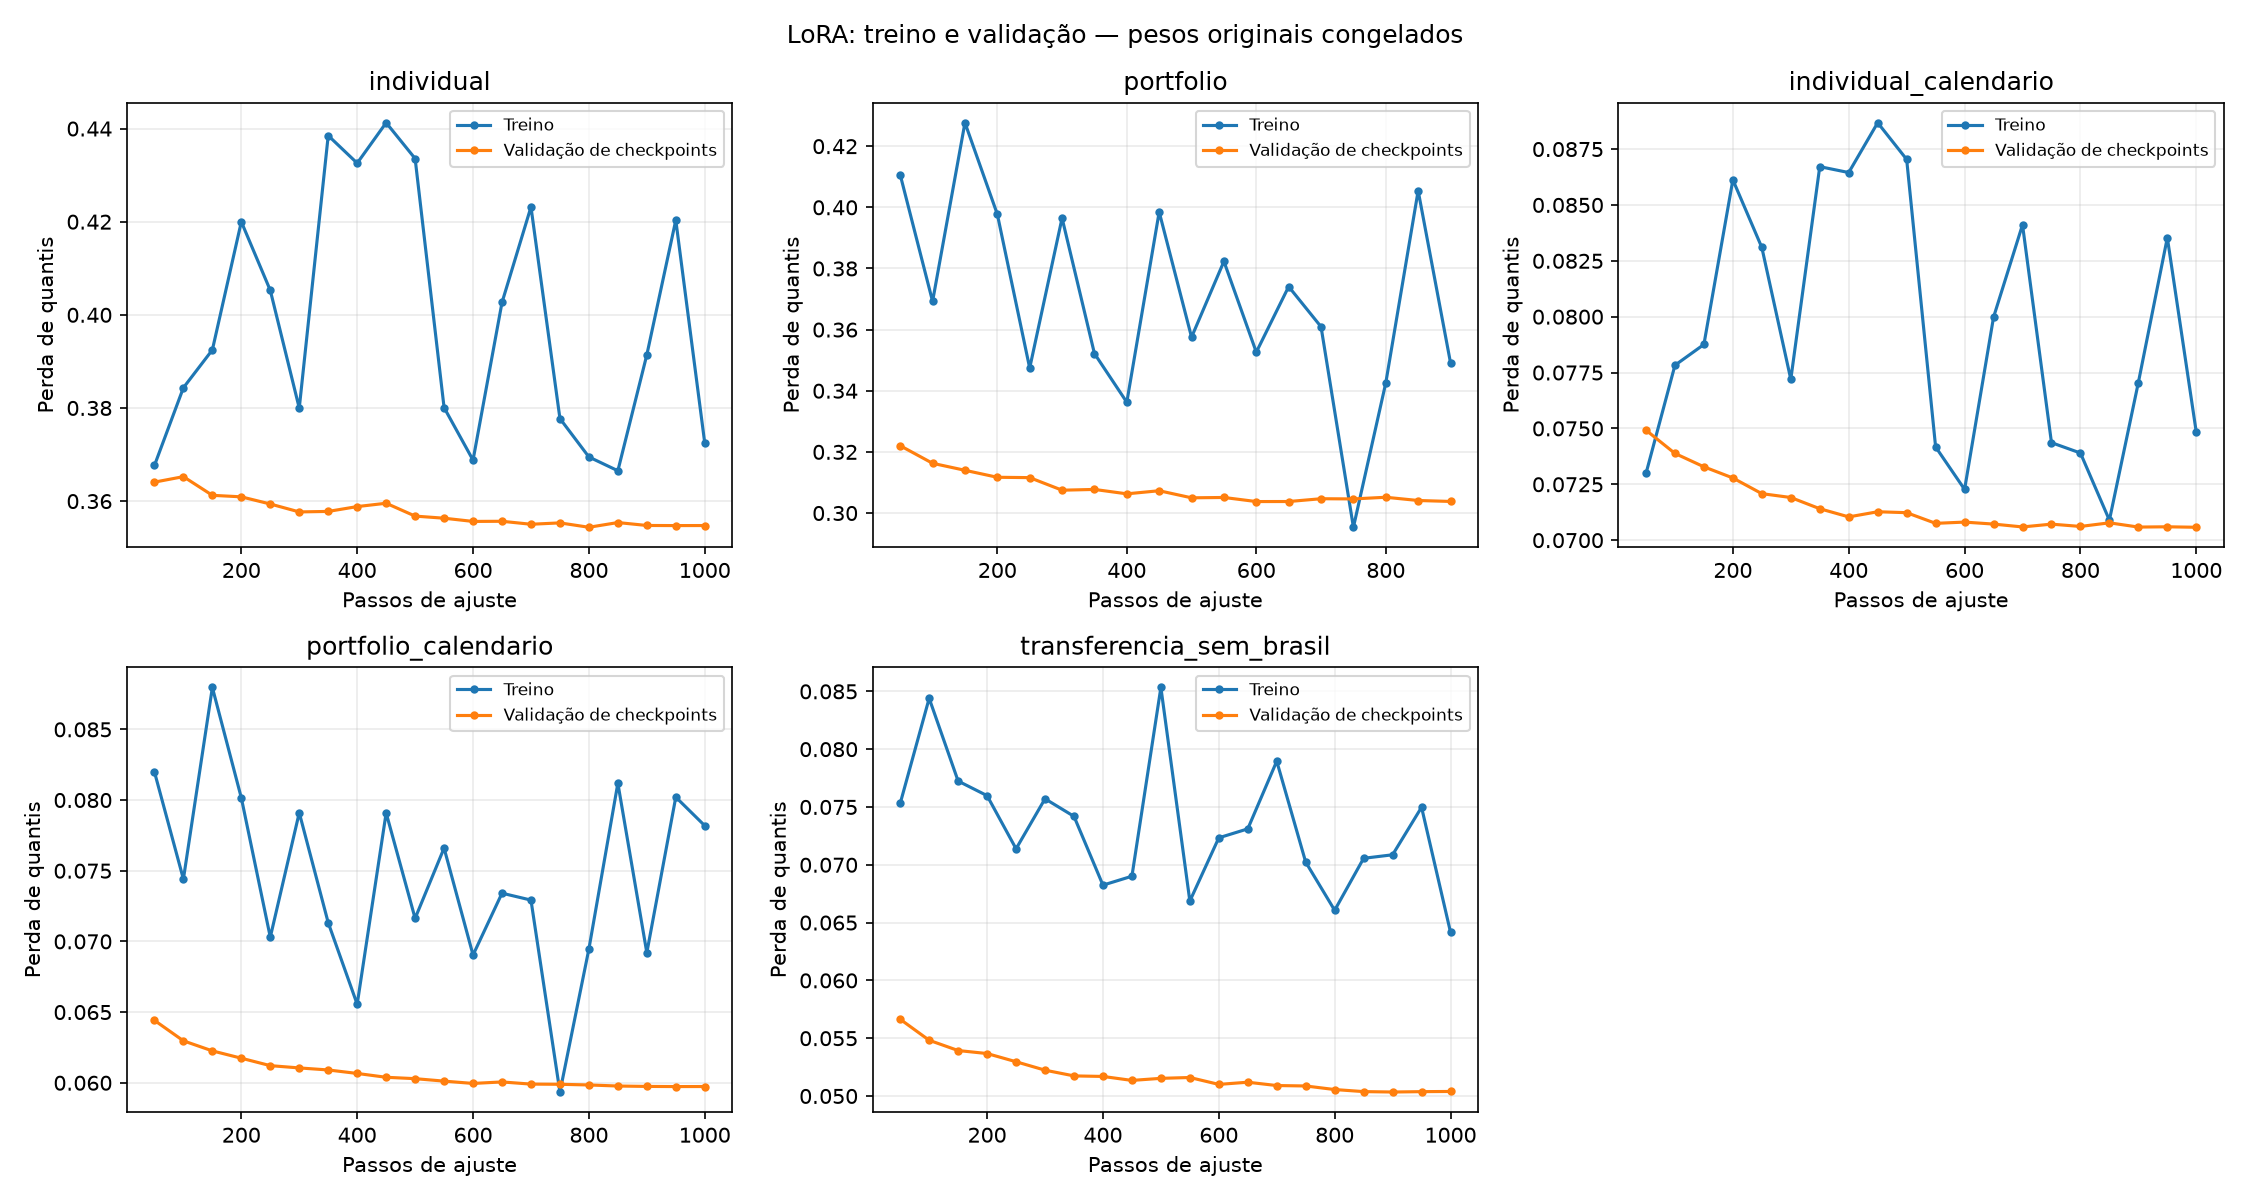

Relatório: C:\Users\Camille\Documents\UFJF\TCC\Leopoldo\experimentos\chronos_5min\resultados\relatorio.md


In [11]:
fig, eixos = plt.subplots(2, 3, figsize=(15, 8))
for ax, cenario in zip(eixos.flat, dados_chronos['cfg']['cenarios']):
    pasta = dados_chronos['pasta'] / 'modelos' / cenario['nome']
    hist = pd.DataFrame(json.loads((pasta / 'historico.json').read_text(encoding='utf-8')))
    for coluna, rotulo in [('loss', 'Treino'), ('eval_loss', 'Validação de checkpoints')]:
        pontos = hist.dropna(subset=[coluna])
        ax.plot(pontos.passo, pontos[coluna], marker='.', label=rotulo)
    ax.set(title=cenario['nome'], xlabel='Passos de ajuste', ylabel='Perda de quantis')
    ax.grid(alpha=.25)
    ax.legend(fontsize=8)
eixos.flat[-1].axis('off')
fig.suptitle('LoRA: treino e validação — pesos originais congelados')
fig.tight_layout()
fig.savefig(dados_chronos['out'] / 'curvas_treinamento_lora.png', dpi=150)
display(Image(filename=str(dados_chronos['out'] / 'curvas_treinamento_lora.png')))
plt.close(fig)
print('Relatório:', dados_chronos['out'] / 'relatorio.md')

In [12]:
# 1. Carregar somente data e potência
df = pd.read_csv(
    "data/processed/brasil/base_5min_brasil.csv.gz"
)

df.columns

Index(['timestamp', 'Active_Power_original', 'Active_Power',
       'registro_original', 'diurno', 'inversores_medidos', 'inversores_proxy',
       'inversores_zero_fisico', 'potencia_estimada',
       'Weather_Temperature_Celsius', 'Weather_Relative_Humidity',
       'Global_Horizontal_Radiation', 'hora_sin', 'hora_cos', 'dia_ano_sin',
       'dia_ano_cos', 'meteo_resolucao_nativa_min', 'meteo_idade_min',
       'temperatura_estacao_original',
       'ghi_estacao_original_escala_nao_validada'],
      dtype='str')

In [14]:

import torch
from chronos import Chronos2Pipeline

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Dispositivo:", DEVICE)

pipeline = Chronos2Pipeline.from_pretrained(
    "amazon/chronos-2",
    device_map=DEVICE
)

print("Chronos-2 carregado.")


Dispositivo: cuda


Loading weights: 100%|██████████| 170/170 [00:01<00:00, 158.68it/s]

Chronos-2 carregado.


In [28]:
# 1. Carregar somente data e potência
df = pd.read_csv(
    "data/processed/brasil/base_5min_brasil.csv.gz",
    usecols=["timestamp", "Active_Power"]
)
df['Active_Power'].values

array([0., 0., 0., ..., 0., 0., 0.], shape=(105120,))

In [ ]:

df = df.rename(columns={
    "timestamp": "timestamp",
    "Active_Power": "target"
})

df["timestamp"] = pd.to_datetime(df["timestamp"])
df["target"] = pd.to_numeric(df["target"], errors="coerce")

df = (
    df.dropna(subset=["timestamp"])
      .sort_values("timestamp")
      .drop_duplicates("timestamp")
      .set_index("timestamp")
      .asfreq("D")
)

df['target'].values

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0.

In [18]:

import pandas as pd

# 2. Selecionar últimos 14 dias
JANELA = 14

context_df = df.tail(JANELA).copy()

if context_df["target"].isna().any():
    raise ValueError(
        "Existem dias sem potência na janela. "
        "Escolha uma janela com dias consecutivos."
    )

context_df = context_df.reset_index()
context_df["id"] = "Leopoldo"

context_df = context_df[
    ["id", "timestamp", "target"]
]

# 3. Prever potência do próximo dia
pred_df = pipeline.predict_df(
    context_df,
    prediction_length=1,
    quantile_levels=[0.1, 0.5, 0.9],
    id_column="id",
    timestamp_column="timestamp",
    target="target",
    freq="D"
)

display(pred_df)

print(
    "Potência prevista:",
    round(float(pred_df["predictions"].iloc[0]), 3),
    "kW"
)


,id,timestamp,target_name,predictions,0.1,0.5,0.9
0,Leopoldo,2026-01-01,target,1.830754e-08,-4.586057e-08,1.830754e-08,1.012370e-07


Potência prevista: 0.0 kW
